In [16]:
import os
import cv2
import matplotlib.pyplot as plt
import random
from PIL import Image
import torch
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
import torchvision.models as models
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

In [17]:
# folder paths
dataset_path = r'C:/Users/Owner/Documents/Lagoon_Public_Art_V26B/Photos/'

# training directory
train_dir = os.path.join(dataset_path, 'Train')

# file names
classes = os.listdir(train_dir)

In [18]:
transform = transforms.Compose([
	transforms.Resize((3008,2000)),
	transforms.ToTensor(),
	transforms.Normalize([0.485,0.465,0.406],
		[0.229,0.224,0.225])
])

In [19]:
train_dataset = ImageFolder(os.path.join(dataset_path, 'Train'), transform = transform)
val_dataset = ImageFolder(os.path.join(dataset_path, 'Val'), transform = transform)
test_dataset = ImageFolder(os.path.join(dataset_path, 'Test'), transform = transform)

train_loader = DataLoader(train_dataset, batch_size = 16, shuffle = True, num_workers = 0)
val_loader = DataLoader(val_dataset, batch_size = 8, shuffle = False)
test_loader = DataLoader(test_dataset, batch_size = 8, shuffle = False)

In [20]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') # works with nvidia gpus

model = models.resnet18(pretrained = True)

for param in model.parameters():
	param.requires_grad = False

num_classes = len(train_dataset.classes)
model.fc = nn.Linear(model.fc.in_features, num_classes)

model = model.to(device)

optimizer = optim.Adam(model.parameters(), lr = 0.001)
criterion = nn.CrossEntropyLoss()

c:\Users\Owner\anaconda3\envs\PubArt\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Owner\anaconda3\envs\PubArt\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [21]:
def train_one_epoch(model, loader):
	model.train()
	running_loss = 0

	for images, labels in loader:
		images, labels = images.to(device), labels.to(device)
		optimizer.zero_grad()
		outputs = model(images)
		loss = criterion(outputs, labels)
		loss.backward()
		optimizer.step()
		running_loss += loss.item()

	return running_loss / len(loader)

In [22]:
def evaluate(model, loader): 
	model.eval()
	correct = 0
	total = 0

	with torch.no_grad():
		for images, labels in loader:
			images, labels = images.to(device), labels.to(device)
			outputs = model(images)
			_, predicted = torch.max(outputs.data, 1)
			total += labels.size(0)
			correct += (predicted == labels).sum().item()

	return correct / total

In [23]:
epochs = 5
print('test')
for epoch in range(epochs):
	train_loss = train_one_epoch(model, train_loader)
	val_acc = evaluate(model, val_loader)
	print(f"Epoch {epoch + 1}, Train Loss: {train_loss:.4f}, Validation Accuracy: {val_acc:.4f}")
print('test')

test
Epoch 1, Train Loss: 1.4414, Validation Accuracy: 0.6000
Epoch 2, Train Loss: 1.2566, Validation Accuracy: 0.6769
Epoch 3, Train Loss: 1.1963, Validation Accuracy: 0.6308
Epoch 4, Train Loss: 1.1277, Validation Accuracy: 0.6308
Epoch 5, Train Loss: 1.0730, Validation Accuracy: 0.6462
test


In [24]:
test_acc = evaluate(model, test_loader)

In [25]:
print(f"Test Accuracy: {test_acc:.4f}")

Test Accuracy: 0.8983


In [28]:
def visualize_predictions(model, loader, n=5):
    model.eval
    images_shown = 0
    class_names = train_dataset.classes

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            for i in range(n):
                img = images[i].cpu().permute(1,2,0).numpy()
                plt.imshow((img))
                plt.title(f'True: {class_names[labels[i]]}, Pred: {class_names[preds[i]]}')
                plt.axis('off')
                plt.show()

                images_shown += 1

                if images_shown >= n:
                    return

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..1.6152923].


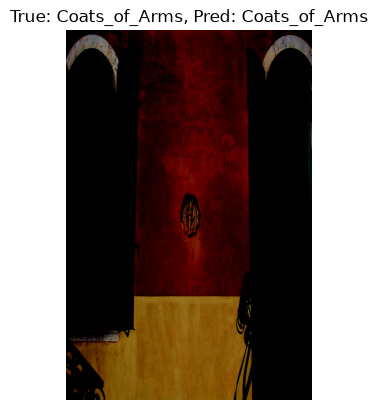

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..1.4199566].


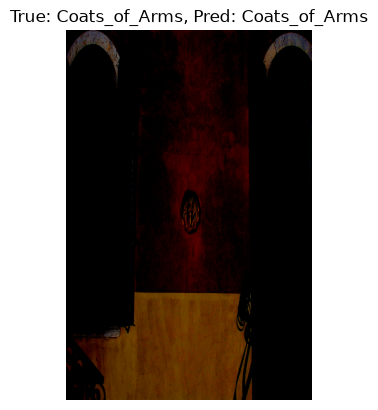

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..0.96455175].


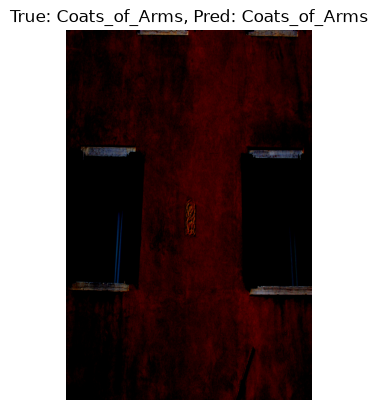

In [30]:
visualize_predictions(model, test_loader, 3)

In [2]:
import joblib

In [3]:
model_data = {
    'model_state_dict' : model.state_dict(),
    'class_to_idx': train_dataset.class_to_idx
}

NameError: name 'model' is not defined

In [1]:
joblib.dump(model_data, 'artifact_classifier_model.pkl')

NameError: name 'joblib' is not defined